# Lezione 1 — Python da zero, regressione lineare e logistica
**Machine Learning for the Humanities · 4 novembre**

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/lessons/01_python_da_zero_regressione.ipynb)

**Laboratorio:** il nostro primo programma funzionante in Colab.

Il filo rosso del corso è **la felicità**: come ne parlano i testi, e che cosa una macchina riesce (o non riesce) a coglierne.
Oggi ci chiediamo: *nella Divina Commedia le parole felici aumentano man mano che Dante sale verso il Paradiso?*

### Obiettivi di apprendimento
Alla fine della lezione saprete:
1. eseguire celle di codice in un notebook (Colab o Jupyter);
2. usare variabili, stringhe, liste e un ciclo `for`;
3. leggere una tabella di dati con `pandas`;
4. spiegare con parole vostre che cosa fanno una **regressione lineare** e una **regressione logistica**;
5. addestrarle con `scikit-learn` e leggerne il risultato con spirito critico.

## 0. Come funziona un notebook
Un notebook alterna **testo** (come questo) e **celle di codice**. Per eseguire una cella: cliccateci sopra e premete **Shift + Invio**.
Il risultato compare sotto la cella. L'ordine conta: eseguite le celle dall'alto in basso.

> Se qualcosa si rompe: menu *Runtime → Riavvia ed esegui tutto* (Colab) oppure *Kernel → Restart & Run All* (Jupyter).

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


## 1. Python come calcolatrice
Python sa fare i conti. Quanti anni sono passati dalla nascita di Dante (1265)?

In [2]:
2026 - 1265

761

## 2. Variabili: dare un nome alle cose
Una **variabile** è un'etichetta attaccata a un valore. Il segno `=` vuol dire "metti questo valore in questa etichetta".

In [3]:
autore = "Dante Alighieri"
nascita = 1265
morte = 1321
eta = morte - nascita
print(autore, "visse", eta, "anni")
print(f"{autore} nacque nel {nascita}.")   # f-string: le graffe {} inseriscono il valore

Dante Alighieri visse 56 anni
Dante Alighieri nacque nel 1265.


## 3. Stringhe: il testo per Python
Una **stringa** è una sequenza di caratteri tra virgolette. Possiamo misurarla, trasformarla, cercarci dentro.

In [4]:
parola = "felicità"
print(len(parola))          # quanti caratteri
print(parola.upper())       # maiuscolo
print(parola[0], parola[-1])  # primo e ultimo carattere (si conta da 0!)
print("lic" in parola)      # contiene "lic"? True = vero, False = falso

8
FELICITÀ
f à
True


## 4. Liste e cicli
Una **lista** raccoglie più valori tra parentesi quadre. Un ciclo `for` ripete la stessa operazione su ogni elemento.

Le sei parole qui sotto vengono dal *lessico della felicità* del corso: ognuna ha una sfumatura diversa.

In [5]:
import pandas as pd    # pandas: la libreria per le tabelle
lessico = pd.read_csv(DATI / "lessico_felicita.csv")
lessico[lessico["lingua"] == "italiano"][["parola", "sfumatura"]]

,parola,sfumatura
0,felicità,"la felicità come stato, spesso idealizzata; po..."
1,gioia,"più luminosa e improvvisa della felicità, meno..."
2,allegria,buonumore leggero e sociale: l'atmosfera di un...
3,contentezza,"la soddisfazione quieta, sufficiente; meno int..."
4,letizia,"gioia arcaica e letteraria, con echi danteschi..."
5,beatitudine,"beatitudine religiosa e filosofica, la felicit..."


In [6]:
parole_felici = ["felicità", "gioia", "allegria", "contentezza", "letizia", "beatitudine"]

for p in parole_felici:
    print(p, "ha", len(p), "lettere")

felicità ha 8 lettere
gioia ha 5 lettere
allegria ha 8 lettere
contentezza ha 11 lettere
letizia ha 7 lettere
beatitudine ha 11 lettere


Un ciclo può contenere una **condizione** (`if`): fai qualcosa solo se è vero.

In [7]:
for p in parole_felici:
    if len(p) > 8:
        print(p, "è una parola lunga")
    else:
        print(p, "è una parola corta")

felicità è una parola corta
gioia è una parola corta
allegria è una parola corta
contentezza è una parola lunga
letizia è una parola corta
beatitudine è una parola lunga


## 5. Il nostro primo programma: contare le parole felici
Prima ci serve una piccola **funzione** che spezza un testo in parole. Una funzione è un pezzo di codice con un nome,
che possiamo riusare. Non serve capire ogni simbolo: `re.findall(r"\w+", ...)` vuol dire "trova tutte le sequenze di lettere".

Poi carichiamo l'elenco delle **forme** delle parole felici (*felice, felici, lieto, lieta, beati…*).

In [8]:
import re
import pandas as pd

def parole(testo):
    """Trasforma un testo in una lista di parole minuscole."""
    return re.findall(r"\w+", testo.lower())

famiglie = pd.read_csv(DATI / "famiglie_felicita_it.csv")
FORME_FELICI = set(famiglie["forma"])
print(len(FORME_FELICI), "forme felici, per esempio:", sorted(FORME_FELICI)[:8])

35 forme felici, per esempio: ['allegra', 'allegramente', 'allegre', 'allegrezza', 'allegri', 'allegria', 'allegro', 'beata']


In [9]:
verso = "E intanto riede alla sua parca mensa, fischiando, il zappatore, e seco pensa al dì del suo riposo."
print(parole(verso))

['e', 'intanto', 'riede', 'alla', 'sua', 'parca', 'mensa', 'fischiando', 'il', 'zappatore', 'e', 'seco', 'pensa', 'al', 'dì', 'del', 'suo', 'riposo']


Ora leggiamo i **Canti** di Leopardi e prendiamo *Il sabato del villaggio*: quante parole felici contiene?

In [10]:
canti = pd.read_csv(DATI / "leopardi_canti.csv")
sabato = canti[canti["titolo"] == "Il sabato del villaggio"]["testo"].iloc[0]
print(sabato[:400])

La donzelletta vien dalla campagna,
In sul calar del sole,
Col suo fascio dell'erba; e reca in mano
Un mazzolin di rose e di viole,
Onde, siccome suole,
Ornare ella si appresta
Dimani, al dì di festa, il petto e il crine.
Siede con le vicine
Su la scala a filar la vecchierella,
Incontro là dove si perde il giorno;
E novellando vien del suo buon tempo,
Quando ai dì della festa ella si ornava,
Ed an


In [11]:
conteggio = 0
trovate = []
for p in parole(sabato):
    if p in FORME_FELICI:
        conteggio = conteggio + 1
        trovate.append(p)

print("Parole totali:", len(parole(sabato)))
print("Parole felici:", conteggio, trovate)

Parole totali: 296
Parole felici: 4 ['lieto', 'gioia', 'allegrezza', 'lieta']


🎉 Questo è un programma completo: **legge** dei dati, li **elabora** con un ciclo e una condizione, **stampa** un risultato.

Notate però che il conteggio è *ingenuo*. La felicità del *Sabato* è un'**attesa** (i tedeschi direbbero *Vorfreude*, la gioia
del pregustare), e la poesia finisce dicendo che la festa porterà "tristezza e noia". Il programma vede le parole *lieto* e *gioia*,
non vede l'ironia. Contare parole non è capire un testo: è la prima domanda critica del corso.

## 6. Da un testo a una tabella
Facciamo lo stesso per **tutti i 100 canti** della Commedia. Ogni riga della tabella è un canto.

In [12]:
dc = pd.read_csv(DATI / "commedia_canti.csv")
dc["n_parole"] = dc["testo"].apply(lambda t: len(parole(t)))
dc["n_tipi"] = dc["testo"].apply(lambda t: len(set(parole(t))))   # parole diverse (vocabolario)
dc["n_felici"] = dc["testo"].apply(lambda t: sum(p in FORME_FELICI for p in parole(t)))
dc["tasso_felicita"] = dc["n_felici"] / dc["n_parole"] * 1000     # parole felici ogni 1000
dc[["cantica", "canto", "posizione", "n_parole", "n_tipi", "n_felici", "tasso_felicita"]].head()

,cantica,canto,posizione,n_parole,n_tipi,n_felici,tasso_felicita
0,Inferno,I,1,993,505,4,4.028197
1,Inferno,II,2,1034,495,3,2.901354
2,Inferno,III,3,956,495,1,1.046025
3,Inferno,IV,4,1021,527,3,2.938296
4,Inferno,V,5,967,519,1,1.034126


In [13]:
dc.groupby("cantica", sort=False)["tasso_felicita"].mean().round(2)

cantica
Inferno       0.72
Purgatorio    1.49
Paradiso      2.99
Name: tasso_felicita, dtype: float64

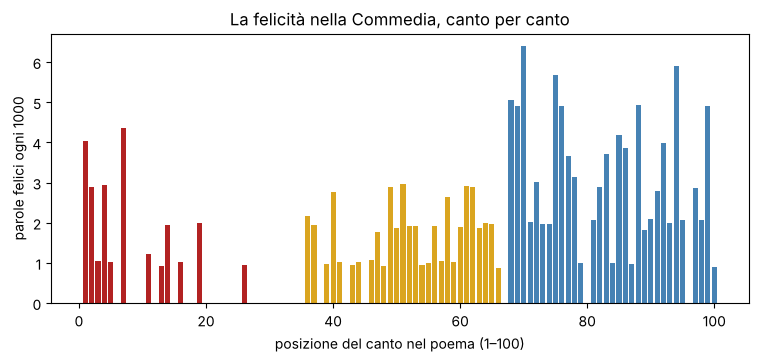

In [14]:
import matplotlib.pyplot as plt

colori = {"Inferno": "firebrick", "Purgatorio": "goldenrod", "Paradiso": "steelblue"}
plt.figure(figsize=(9, 3.5))
plt.bar(dc["posizione"], dc["tasso_felicita"], color=dc["cantica"].map(colori))
plt.xlabel("posizione del canto nel poema (1–100)")
plt.ylabel("parole felici ogni 1000")
plt.title("La felicità nella Commedia, canto per canto")
plt.show()

## 7. Regressione lineare: tracciare la retta migliore
Una **regressione lineare** cerca la retta che passa "il più vicino possibile" a una nuvola di punti:

$$ y = a + b \cdot x $$

- $x$ è ciò che conosciamo (per esempio la lunghezza di un canto),
- $y$ è ciò che vogliamo prevedere (per esempio quante parole *diverse* usa),
- $b$ è la **pendenza**: di quanto cresce $y$ quando $x$ cresce di 1; $a$ è l'**intercetta**.

Il computer *impara* $a$ e $b$ dai dati: è il primo esempio di *machine learning* del corso.

### Esempio A: canti più lunghi hanno un vocabolario più ricco?

In [15]:
from sklearn.linear_model import LinearRegression

X = dc[["n_parole"]]     # doppie parentesi: X è una tabella (anche con una sola colonna)
y = dc["n_tipi"]

modello = LinearRegression()
modello.fit(X, y)        # "fit" = addestra

print("pendenza b:", round(modello.coef_[0], 3))
print("intercetta a:", round(modello.intercept_, 1))
print("R² (quanto bene la retta spiega i dati, da 0 a 1):", round(modello.score(X, y), 3))

pendenza b: 0.36
intercetta a: 152.1
R² (quanto bene la retta spiega i dati, da 0 a 1): 0.625


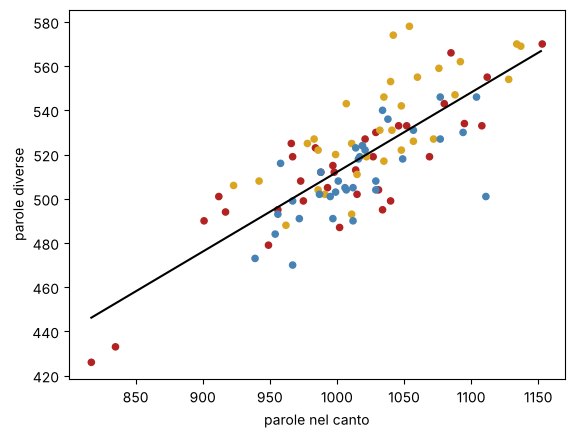

Un canto di 1500 parole dovrebbe avere circa 692 parole diverse


In [16]:
plt.scatter(dc["n_parole"], dc["n_tipi"], c=dc["cantica"].map(colori), s=20)
xs = pd.DataFrame({"n_parole": range(int(dc["n_parole"].min()), int(dc["n_parole"].max()))})
plt.plot(xs["n_parole"], modello.predict(xs), color="black")
plt.xlabel("parole nel canto"); plt.ylabel("parole diverse"); plt.show()

nuovo = pd.DataFrame({"n_parole": [1500]})
print("Un canto di 1500 parole dovrebbe avere circa", round(modello.predict(nuovo)[0]), "parole diverse")

### Esempio B: la felicità cresce lungo il viaggio?
Ora $x$ è la posizione del canto (1 = primo canto dell'Inferno, 100 = ultimo del Paradiso) e $y$ il tasso di felicità.

Ogni canto in avanti: +0.027 parole felici ogni 1000
R²: 0.229


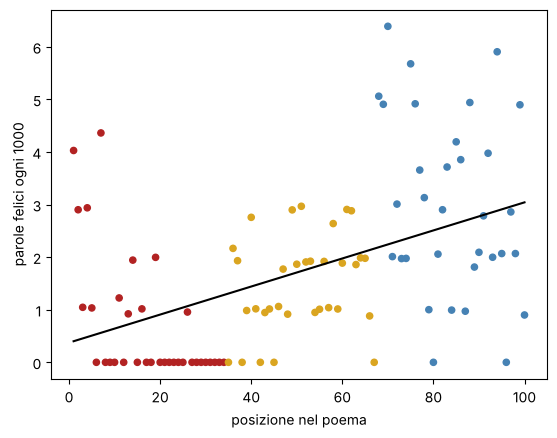

In [17]:
X = dc[["posizione"]]
y = dc["tasso_felicita"]
reg = LinearRegression().fit(X, y)
print(f"Ogni canto in avanti: {reg.coef_[0]:+.3f} parole felici ogni 1000")
print("R²:", round(reg.score(X, y), 3))

plt.scatter(dc["posizione"], y, c=dc["cantica"].map(colori), s=20)
plt.plot(dc["posizione"], reg.predict(X), color="black")
plt.xlabel("posizione nel poema"); plt.ylabel("parole felici ogni 1000"); plt.show()

**Come leggere il risultato.** La pendenza è positiva: la felicità *lessicale* cresce lungo il poema. Ma l'R² è basso:
la retta spiega solo una parte delle differenze tra un canto e l'altro. Inoltre una retta è un'ipotesi molto semplice
(magari il salto avviene a un certo punto, non in modo graduale). Un modello è un **riassunto**, non una spiegazione.

## 8. Regressione logistica: rispondere sì o no
Spesso la domanda non è "quanto?" ma "**sì o no?**". *Questo canto è del Paradiso?*

La **regressione logistica** trasforma la retta in una curva a "S" che va da 0 a 1: il risultato è una **probabilità**.
Se la probabilità supera 0,5 il modello risponde "sì". Nonostante il nome, è un metodo di **classificazione**.

In [18]:
from sklearn.linear_model import LogisticRegression

dc["e_paradiso"] = (dc["cantica"] == "Paradiso").astype(int)   # 1 = sì, 0 = no
X = dc[["tasso_felicita"]]
y = dc["e_paradiso"]

clf = LogisticRegression()
clf.fit(X, y)

prove = pd.DataFrame({"tasso_felicita": [0, 1, 2, 4, 6]})
prove["prob_paradiso"] = clf.predict_proba(prove)[:, 1].round(2)
prove

,tasso_felicita,prob_paradiso
0,0,0.08
1,1,0.18
2,2,0.34
3,4,0.75
4,6,0.95


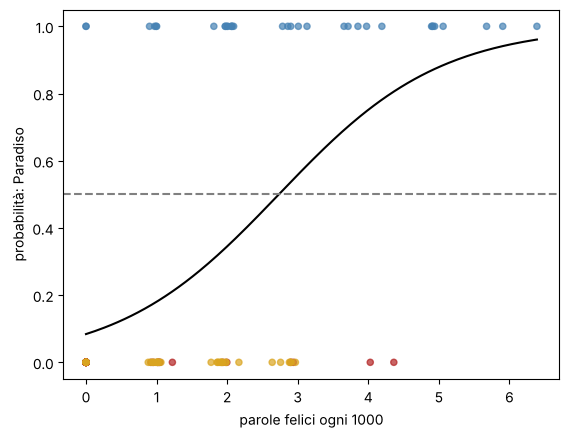

Risposte giuste sui 100 canti: 76 %


In [19]:
import numpy as np
xs = pd.DataFrame({"tasso_felicita": np.linspace(0, dc["tasso_felicita"].max(), 200)})
plt.scatter(dc["tasso_felicita"], dc["e_paradiso"], c=dc["cantica"].map(colori), s=20, alpha=0.7)
plt.plot(xs, clf.predict_proba(xs)[:, 1], color="black")
plt.axhline(0.5, ls="--", color="gray")
plt.xlabel("parole felici ogni 1000"); plt.ylabel("probabilità: Paradiso"); plt.show()

print("Risposte giuste sui 100 canti:", round(clf.score(X, y) * 100), "%")

⚠️ Abbiamo misurato l'accuratezza **sugli stessi canti** usati per addestrare: è come correggere un compito con le soluzioni sotto gli occhi.
E poi: il 33% dei canti è del Paradiso, quindi rispondere sempre "no" darebbe già il 67%. Torneremo su questo nella lezione dell'11 novembre.

## Riepilogo
| Concetto | In Python | A che cosa serve |
|---|---|---|
| variabile | `nascita = 1265` | dare un nome a un valore |
| lista e ciclo | `for p in lista:` | ripetere un'operazione |
| tabella | `pd.read_csv(...)` | leggere dati strutturati |
| regressione lineare | `LinearRegression().fit(X, y)` | prevedere un **numero** |
| regressione logistica | `LogisticRegression().fit(X, y)` | prevedere **sì/no** con una probabilità |

## Esercizi
Le soluzioni sono in `solutions/01_python_da_zero_regressione_soluzioni.ipynb`. Provateci prima da soli!

**Esercizio 1 — Una parola alla volta.** Scrivete un programma che, data la variabile `parola`, stampi: quante lettere ha,
la prima e l'ultima lettera, e se è una forma felice (`parola in FORME_FELICI`). Provatelo con *lieta*, *dolore*, *beati*.

**Esercizio 2 — La poesia più felice.** Calcolate il tasso di felicità (parole felici ogni 1000) per ognuna delle 40 poesie
dei *Canti* di Leopardi e mostrate le 5 più "felici". Leggete l'inizio della prima: è davvero una poesia felice?

**Esercizio 3 — Leopardi e Dante.** Addestrate una regressione lineare `n_parole → n_tipi` sui Canti di Leopardi.
Confrontate la pendenza con quella di Dante. Che cosa vuol dire, a parole, che una pendenza è più alta?

In [20]:
# Esercizio 1
parola = "lieta"

In [21]:
# Esercizio 2

In [22]:
# Esercizio 3